# Can a molecule change but not fall apart? Find the change in an amino acid's spectra

You'll tell an amino acid that stays whole from one that changes without breaking down.

Every amino acid has a **backbone** (the part that links into a protein chain) and its own **side
chain** (the part that differs between amino acids). The backbone is the same in all of them except
proline, whose nitrogen sits in a ring. Most amino acids keep their backbone in concentrated
sulfuric acid. Some change their side chain. Here you learn to tell the two apart.

Boxes headed **RECORD YOUR ANSWER** are where you write something. You compare with the paper at
the end.

| Part | What you do | Time |
|---|---|---|
| 1 | Read a stable amino acid (worked) | 10 min |
| 2 | Follow a worked change, then predict and load your case | 20 min |
| 3 | Find the backbone signal, follow every peak, check the carbon spectrum | 25 min |
| 4 | Write your verdict and compare | 20 min |
| 5 | Extra: catch a change that finishes before the first spectrum (serine) | 30 min |

Parts 1 to 4 go with the NMR project step "Can a molecule change but not fall apart?". Part 5 goes
with the Extra "Can a molecule change before you measure it?".

Data: M. D. Seager, S. Seager, Bains and Petkowski, Zenodo [10.5281/zenodo.8381013](https://doi.org/10.5281/zenodo.8381013), CC BY 4.0. Paper: *Astrobiology* 24, 386 (2024).

In [1]:
# Setup. In Colab this first installs the training package and the Rakiura helper (about 30 s).
import importlib.util

if importlib.util.find_spec("nmrtrain") is None:
    %pip install -q "nmrtrain @ git+https://github.com/Rakiura-Inc/morning-star-nmr@main"
if importlib.util.find_spec("rakiura") is None:
    %pip install -q "rakiura @ git+https://github.com/Rakiura-Inc/rakiura-py@main"
import matplotlib.pyplot as plt
import nmrglue as ng  # the standard Python library for reading and processing NMR data
import numpy as np
from scipy.signal import find_peaks

import nmrtrain as nt  # this course's plumbing: downloads, checks, your answers, the hand-in

NOTEBOOK = "notebooks/03_amino_acid_side_chains.ipynb"
MODE = nt.portal.connect(NOTEBOOK)

Not connected to Rakiura. Your work stays on this computer. Run the Connect cell below to tick steps on Rakiura.


> **CONNECT TO RAKIURA (optional, recommended)**
>
> **What it does:** ticks your checklist on the step as you go and attaches your figures to it. Nothing is sent until you connect.
>
> **How:** run the cell below, open the link it prints, check the code matches the one printed here, and click Allow. In Colab you do this once per session. To skip the click, add your key as a Colab secret named `RAKIURA_KEY` (the key icon on the left; get the key in Rakiura under Settings > Notebook key).
>
> **Skipping it is fine:** your work is kept on this computer, and you can attach your files on the step page instead.

In [2]:
# Connect to Rakiura (optional). Open the link it prints, check the code matches, click Allow.
MODE = nt.portal.connect(NOTEBOOK, sign_in=True)

Not connected to Rakiura. Your work stays on this computer. Run this cell again to try once more, or attach your files on the step page.


## Part 1: A stable one, worked

The next cell stacks alanine in 98% acid at 1 day, 1 week (8 days) and 1 month. Its alpha hydrogen (on the
backbone carbon next to the nitrogen, about 4.6 ppm) and its methyl (about 2.0 ppm) do not move.

In [3]:
# How every spectrum in this notebook is read, with nmrglue.
def read_spectrum(zip_path):
    """The spectrum the instrument processed, with its ppm axis and labels (sample, acid, time)."""
    folder = nt.io.experiment_folder(zip_path)  # unzipped once, into nmr_data/
    # Bruker keeps the spectrum it processed in pdata/1; dic holds the instrument's settings.
    dic, data = ng.bruker.read_pdata(f"{folder}/pdata/1")
    # udic: the axis settings (number of points, spectral width, spectrometer frequency) from dic.
    udic = ng.bruker.guess_udic(dic, data)
    ppm = ng.fileiobase.uc_from_udic(udic).ppm_scale()  # the instrument's ppm scale, high to low
    return nt.io.labelled(zip_path, dic, ppm, data)

In [4]:
AMINO_ACID_SPECTRA = "8381013"  # Zenodo record: M. D. Seager et al., CC BY 4.0
alanine_files = nt.data.fetch(AMINO_ACID_SPECTRA, "alanine", acid="98%")
alanine = [read_spectrum(path) for path in alanine_files]  # 1 day, 1 week, 1 month

ALA 1H 98% w/w D2SO4: 3 spectra, all cached
Data: Seager, M. D.; Seager, S.; Bains, W.; Petkowski, J. J. (2023). Stability of Biogenic Amino Acids in Concentrated Sulfuric Acid: Implications for the Habitability of Venus' Clouds (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.8381013 (CC BY 4.0). Paper: Seager et al. 2024, Astrobiology 24, 386 (ADS 2024AsBio..24..386S).


In [5]:
def scaled(spectrum, scale_region):
    """The intensity divided by its tallest point inside scale_region (low, high ppm), so that point
    is 1. With scale_region None, the tallest point anywhere (in a hydrogen spectrum in this acid,
    the acid's own peak)."""
    if scale_region is None:
        return spectrum.intensity / spectrum.intensity.max()
    low_ppm, high_ppm = scale_region
    _, intensity_in_region = spectrum.region(low_ppm, high_ppm)  # region gives (ppm, intensity)
    return spectrum.intensity / intensity_in_region.max()

In [6]:
def plot_stack(spectra, ppm_range, *, scale_region, title, labels=None, ax=None, offset=1.2):
    """Traces stacked bottom to top in the order given, each scaled by scaled(), then raised by
    offset. Everything after the * is given by name: plot_stack(spectra, (0, 13), title=...)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))
    colours = plt.cm.viridis(np.linspace(0.0, 0.85, len(spectra)))  # dark to light, short of yellow
    for number, spectrum in enumerate(spectra):
        label = labels[number] if labels else spectrum.time_label
        trace = scaled(spectrum, scale_region) + offset * number
        ax.plot(spectrum.ppm, trace, lw=0.8, color=colours[number], label=label)
    ax.set_xlim(ppm_range[1], ppm_range[0])  # NMR convention: high ppm on the left
    ax.set_ylim(-0.2, offset * (len(spectra) - 1) + 1.4)
    ax.set_yticks([])  # the heights are scaled, so their numbers mean nothing
    ax.set_xlabel("chemical shift (ppm)")
    ax.set_title(title)
    handles, names = ax.get_legend_handles_labels()  # listed top trace first, like the stack
    ax.legend(handles[::-1], names[::-1], frameon=False, fontsize=8, loc="upper left")
    return ax.figure

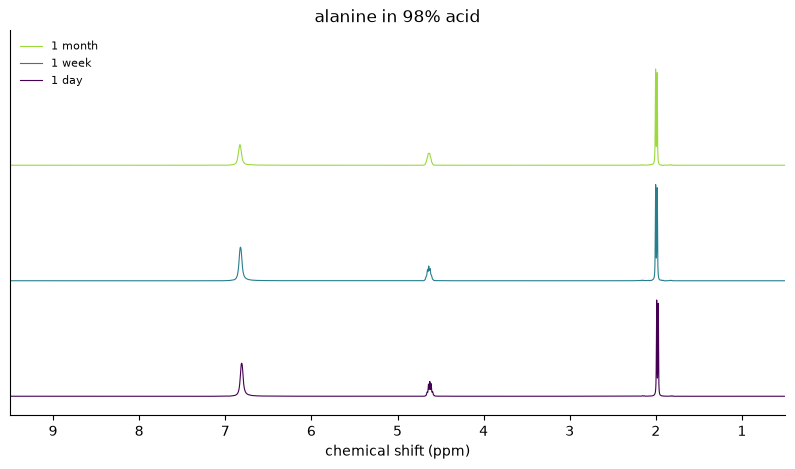

In [7]:
title = "alanine in 98% acid"
fig_alanine = plot_stack(alanine, ppm_range=(0.5, 9.5), scale_region=(0.5, 9.5), title=title)
plt.show()

In [8]:
def group_lines(lines, group_ppm):
    """Lines (ppm, height), low ppm first, closer than group_ppm to the line before belong to the
    same signal: a methyl's two lines are 0.016 ppm apart."""
    groups = []
    previous_ppm = None
    for ppm, height in lines:
        if previous_ppm is not None and ppm - previous_ppm < group_ppm:
            groups[-1].append((ppm, height))
        else:
            groups.append([(ppm, height)])
        previous_ppm = ppm
    return groups

In [9]:
def signal_from(lines):
    """One signal from its lines: their height-weighted centre, how many, and the tallest."""
    total_height = sum(height for _, height in lines)
    centre_ppm = sum(ppm * height for ppm, height in lines) / total_height
    tallest = max(height for _, height in lines)
    return {
        "ppm": round(float(centre_ppm), 3),
        "lines": len(lines),
        "height": round(float(tallest), 3),
    }

In [10]:
def pick_peaks(spectrum, ppm_range, *, min_height, group_ppm=0.03, scale_region=None):
    """The signals between two ppm values, high ppm first, each {"ppm", "lines", "height"}.
    min_height and the heights are shares of the tallest point in ppm_range, or in scale_region
    when you give one (to look for small peaks in a quiet window)."""
    ppm, intensity = spectrum.region(*ppm_range)  # the (low, high) pair, unpacked
    if scale_region is None:
        heights = intensity / intensity.max()
    else:
        _, intensity_in_region = spectrum.region(*scale_region)
        heights = intensity / intensity_in_region.max()
    # A line must reach min_height and stand 0.02 above the dips beside it (ripples do not).
    found, _ = find_peaks(heights, height=min_height, prominence=0.02)
    lines = sorted(zip(ppm[found], heights[found]))  # (ppm, height) pairs, low ppm first
    signals = [signal_from(group) for group in group_lines(lines, group_ppm)]
    return signals[::-1]  # high ppm first, the way a spectrum is read

In [11]:
NH3_PPM = 6.82  # alanine's NH3+ signal in 98% acid
NH3_WINDOW_PPM = 0.05  # a picked peak this close to 6.82 ppm is the NH3+ peak

for spectrum in alanine:
    # Where the tallest point within 0.1 ppm of the NH3+ signal sits, and how tall its peak is.
    near = (spectrum.ppm > NH3_PPM - 0.1) & (spectrum.ppm < NH3_PPM + 0.1)
    ppm_near, intensity_near = spectrum.ppm[near], spectrum.intensity[near]
    position = ppm_near[np.argmax(intensity_near)]
    height = 0
    for peak in pick_peaks(spectrum, (0.5, 9.5), min_height=0.03):
        if abs(peak["ppm"] - NH3_PPM) < NH3_WINDOW_PPM:
            height = max(height, peak["height"])
    print(f"{spectrum.time_label:8s} NH3+ signal near {position:.2f} ppm, height {height:.2f}")

1 day    NH3+ signal near 6.81 ppm, height 0.34
1 week   NH3+ signal near 6.82 ppm, height 0.35
1 month  NH3+ signal near 6.83 ppm, height 0.21


### Trap: fading NH signals

The peak near 6.8 ppm shrinks. It comes from the NH3+ hydrogens, which swap with deuterium from the
acid. A fading NH peak is not breakdown.

## Part 2: Predict, then load your case

Asparagine and glutamine each carry an amide group, C(=O)NH2, at the end of the side chain. The
worked case below is asparagine in 81% acid (`"ASN-H"`); your hand-in is asparagine in 98% acid
(`"ASN-K"`). Glutamine in 81% acid (`"GLN-H"`) is there for more practice.

### What you need

After 4 weeks in 81% or 98% acid, 19 of 20 amino acids keep their backbone (the summary card in the bootcamp's first step). Some
change only their side chain. Asparagine and glutamine have the same backbone as alanine, which you
just saw survive. What can happen to their side chains is in the worked case below.

### A worked case: asparagine in 81% acid

Asparagine's side chain ends in an amide group, C(=O)NH2. Aspartic acid's ends in a carboxylic acid
group, COOH. If water swaps the amide's NH2 for OH (deamidation), asparagine becomes aspartic acid
while its backbone stays intact. 81% acid holds more water than 98% acid.

The next cell stacks asparagine in 81% acid at 1 day and 1 month above aspartic acid in 81% acid.
After a month, asparagine has two new peaks near 5.55 and 4.34 ppm. They have the same shape and
spacing as aspartic acid's two peaks (5.48 and 4.28 ppm), but sit about 0.07 ppm further left.
Aspartic acid was measured as a separate sample. By the match rule (Look closer, below), peaks 0.05
to 0.1 ppm apart are not settled by hydrogen spectra alone: the same molecule can sit that far apart
in two samples, but so can a close relative.

The carbon spectra do. In the 13C files of the 1 month folder, the new peaks sit within 0.1 ppm of
aspartic acid's, which is a match for carbon. Carbon peaks spread over about 200 ppm, so a match that
close is strong evidence. By area, 2% of the asparagine had changed at 1 day, 7% at 1 week and about
a quarter at 1 month.

Decision: side chain changed. In 81% acid, asparagine slowly turns into aspartic acid.

Aspartic acid here is a reference compound: a known compound, measured on its own, that you compare
your spectra with to name a new peak.

In [12]:
# Asparagine in 81% acid at 1 day and 1 month, and aspartic acid in 81% acid at 1 month.
two_times = ["1day", "1month"]
asparagine_files = nt.data.fetch(AMINO_ACID_SPECTRA, "asparagine", acid="81%", times=two_times)
asparagine_81 = [read_spectrum(path) for path in asparagine_files]
aspartic_files = nt.data.fetch(AMINO_ACID_SPECTRA, "aspartic acid", acid="81%", times=["1month"])
aspartic_acid_81 = [read_spectrum(path) for path in aspartic_files]

ASN 1H 81% w/w D2SO4: 2 spectra, all cached
Data: Seager, M. D.; Seager, S.; Bains, W.; Petkowski, J. J. (2023). Stability of Biogenic Amino Acids in Concentrated Sulfuric Acid: Implications for the Habitability of Venus' Clouds (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.8381013 (CC BY 4.0). Paper: Seager et al. 2024, Astrobiology 24, 386 (ADS 2024AsBio..24..386S).
ASP 1H 81% w/w D2SO4: 1 spectra, all cached
Data: Seager, M. D.; Seager, S.; Bains, W.; Petkowski, J. J. (2023). Stability of Biogenic Amino Acids in Concentrated Sulfuric Acid: Implications for the Habitability of Venus' Clouds (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.8381013 (CC BY 4.0). Paper: Seager et al. 2024, Astrobiology 24, 386 (ADS 2024AsBio..24..386S).


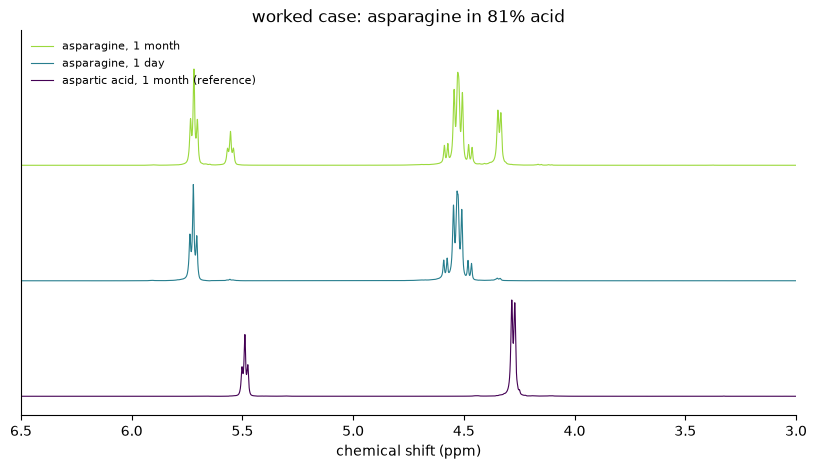

In [13]:
worked_traces = aspartic_acid_81 + asparagine_81  # stacked bottom to top
worked_labels = ["aspartic acid, 1 month (reference)", "asparagine, 1 day", "asparagine, 1 month"]
title = "worked case: asparagine in 81% acid"
fig_worked = plot_stack(
    worked_traces, ppm_range=(3.0, 6.5), scale_region=(3.0, 6.5), title=title, labels=worked_labels
)
plt.show()

In [14]:
# The peaks between 4 and 6 ppm in each trace: set asparagine's new peaks beside aspartic acid's.
for label, spectrum in zip(worked_labels, worked_traces):
    peaks = pick_peaks(spectrum, ppm_range=(4.0, 6.0), min_height=0.03)
    positions = [round(peak["ppm"], 3) for peak in peaks]
    print(f"{label:36s}", positions)

aspartic acid, 1 month (reference)   [5.489, 4.277]
asparagine, 1 day                    [5.722, 4.53]
asparagine, 1 month                  [5.719, 5.554, 4.527, 4.34]


> **RECORD YOUR ANSWER: predict what the acid does to asparagine and glutamine, and pick your case**
>
> **What gets saved:** `MY_PREDICTION`, one prediction per case, saved with the time, and `CASE`, the one you will read.
>
> **Where to look:** Part 1 above, and the paragraph on deamidation.
>
> **How to fill this in:**
> - `"ASN-K"` (asparagine in 98% acid) and `"GLN-H"` (glutamine in 81% acid), each one of:
>   - `"survives"`: nothing changes
>   - `"side chain changed"`: the side chain reacts and the backbone stays
>   - `"breaks down"`: the backbone goes
>   - `"unsure"`
> - `CASE`: the one you will read. Set it to `"ASN-K"` for your hand-in; `"ASN-H"` reruns the worked case in Part 2 and `"GLN-H"` is more practice.
> - The cell after it stacks your case and prints its peak list at each time point.

<details><summary>Stuck? Open hint 1</summary>

Which part of these molecules is new compared with alanine?

</details>

<details><summary>Stuck? Open hint 2</summary>

The backbone is the same as alanine's, which survives. So the question is whether the amide at the
end of the side chain changes, and whether the extra water in 81% acid matters. Guess "survives" if
you think it holds, "side chain changed" if you think it reacts, or "unsure".

</details>

In [15]:
MY_PREDICTION = {
    "ASN-K": ...,  # asparagine in 98%: "survives", "side chain changed", "breaks down" or "unsure"
    "GLN-H": ...,  # glutamine in 81% acid: the same choices
}
nt.record.predict("amino-acid", MY_PREDICTION)

CASE = "ASN-H"  # "ASN-K" for your hand-in, "ASN-H" (the worked case) or "GLN-H"
nt.record.saved("CASE", CASE, "the amino acid you will read")

Fill in at least one prediction above (replace the ...), then run this cell again.


**Saved** `CASE = 'ASN-H'`: the amino acid you will read.

In [16]:
case_name, case_acid = nt.names.case_words(CASE)  # "ASN-K" is ("asparagine", "98%")
case_files = nt.data.fetch(AMINO_ACID_SPECTRA, case_name, acid=case_acid)
case_spectra = [read_spectrum(path) for path in case_files]  # first time point first

ASN 1H 81% w/w D2SO4: 3 spectra, all cached
Data: Seager, M. D.; Seager, S.; Bains, W.; Petkowski, J. J. (2023). Stability of Biogenic Amino Acids in Concentrated Sulfuric Acid: Implications for the Habitability of Venus' Clouds (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.8381013 (CC BY 4.0). Paper: Seager et al. 2024, Astrobiology 24, 386 (ADS 2024AsBio..24..386S).


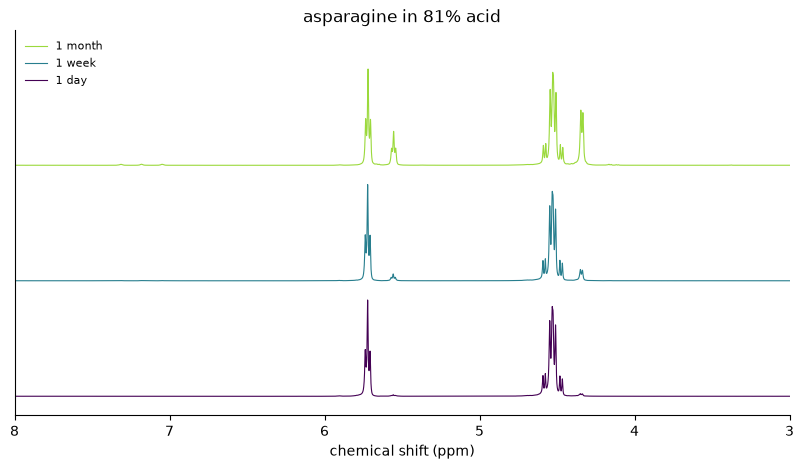

In [17]:
# From 3 to 8 ppm, scaled within 3 to 6.5 ppm, where the hydrogens on carbon sit.
title = f"{case_name} in {case_acid} acid"
fig_case = plot_stack(case_spectra, ppm_range=(3.0, 8.0), scale_region=(3.0, 6.5), title=title)
plt.show()

In [18]:
case_traps = nt.checks.run_traps(case_spectra, norm=(3.0, 6.5), low_ppm=3.0, high_ppm=6.5)

Checks on asparagine in 81% acid: 8 passed, 0 flagged
  nothing to flag


In [19]:
case_peaks_ppm = {}  # time label -> where the peaks between 0.5 and 9.5 ppm sit
for spectrum in case_spectra:
    peaks = pick_peaks(spectrum, (0.5, 9.5), min_height=0.03)
    case_peaks_ppm[spectrum.time] = [peak["ppm"] for peak in peaks]
    print(f"{spectrum.time:7s}", case_peaks_ppm[spectrum.time])
nt.portal.done("amino-acid-stack", figures=[fig_case])  # ticks the stack on Rakiura

1day   

 [8.383, 5.722, 4.53]
1week   [8.383, 5.722, 5.557, 4.53, 4.343]
1month  [8.381, 5.719, 5.554, 4.527, 4.34]
Stacked plot saved (offline mode: kept on this computer).


The stack runs from 3 to 8 ppm, so it shows the NH3+ peak (near 7.2 ppm) as well as the peaks from
hydrogens on carbon. The middle file sits in the folder for 1 week and the stack labels it 1 week;
its file name gives the real time: 9 days for asparagine in 98% acid, 7 days for both cases in 81% acid.

## Part 3: Find the backbone

### What you need

The backbone signal is the alpha hydrogen: the hydrogen on the carbon next to the nitrogen. In this
acid it is usually the highest-ppm signal from hydrogens on carbon of a simple amino acid (alanine's
sits near 4.6 ppm, its methyl near 2.0). Peaks above 6.5 ppm in these amino acids are hydrogens on
nitrogen (alanine's NH3+ sits near 6.8 ppm), not on carbon.

> **RECORD YOUR ANSWER: which peak is the backbone signal?**
>
> **What gets saved:** `BACKBONE_PPM`, one number in ppm.
>
> **Where to look:** the 1 day peak list printed under your stack above.
>
> **How to fill this in:**
> - Write one value from the 1 day list, like `4.62`, with no quotes.

<details><summary>Stuck? Open hint 1</summary>

Cross out the peaks that are hydrogens on nitrogen first.

</details>

<details><summary>Stuck? Open hint 2</summary>

Of the peaks left, the alpha hydrogen sits at the highest ppm, because its carbon carries the
nitrogen. The side-chain CH2 sits at lower ppm.

</details>

In [20]:
BACKBONE_PPM = ...  # one value from the 1 day list above, like 4.62
nt.record.saved("BACKBONE_PPM", BACKBONE_PPM, "your backbone signal, in ppm")

**Not saved yet** `BACKBONE_PPM = ...`: your backbone signal, in ppm. The cell uses a stand-in until you fill it in.

In [21]:
if nt.record.revealed("amino-acid"):
    print(nt.checks.check_backbone(BACKBONE_PPM))

Make your prediction first: fill in the prediction cell above and run it, then run this cell again.


Now follow every peak over the three time points. Look for two things: whether the backbone peak
stays, and whether anything grows next to it. The next cell lists the peaks at both times, at the
first only, and at the last only.

In [22]:
SAME_PEAK_PPM = 0.05  # two peaks this close, at two times, are the same peak


def compare_peaks(first_ppm, last_ppm, tolerance_ppm=SAME_PEAK_PPM):
    """Which peaks are at both times (kept), at the first only (lost) and at the last only
    (new). Two peaks within tolerance_ppm of each other count as the same peak."""
    changes = {"kept": [], "lost": [], "new": []}
    for ppm in first_ppm:
        if any(abs(ppm - later) <= tolerance_ppm for later in last_ppm):
            changes["kept"].append(ppm)
        else:
            changes["lost"].append(ppm)
    for ppm in last_ppm:
        if not any(abs(ppm - earlier) <= tolerance_ppm for earlier in first_ppm):
            changes["new"].append(ppm)
    return changes

In [23]:
def listed(positions_ppm):
    """Positions as '1.99, 2.08', or 'none'."""
    if not positions_ppm:
        return "none"
    return ", ".join(f"{ppm:.2f}" for ppm in positions_ppm)

In [24]:
first, last = case_spectra[0], case_spectra[-1]
changes = compare_peaks(case_peaks_ppm[first.time], case_peaks_ppm[last.time])
print(f"{'at both times':24s}", listed(changes["kept"]))
print(f"{'at the first time only':24s}", listed(changes["lost"]))
print(f"{'at the last time only':24s}", listed(changes["new"]))

at both times            8.38, 5.72, 4.53
at the first time only   none
at the last time only    5.55, 4.34


### A filled example: alanine

Alanine from Part 1, filled in with the reasons. It shows the format; your case's values will
differ.

In [25]:
ALA_EXAMPLE = {
    "call": "survives",  # its hydrogens on carbon stay where they were for a month
    "lost_ppm": [],  # nothing from hydrogens on carbon is gone
    "new_ppm": [],  # nothing new appears
    "kept_ppm": [4.63, 1.99],  # the alpha hydrogen and the methyl
    "product_guess": "none",
    "confidence": "high",
    "note": (
        "The NH3+ signal near 6.8 ppm fades: hydrogens swapping with the acid's deuterium, "
        "not breakdown."
    ),
}

### What you need

- **Lost:** a peak at 1 day that is gone, or much smaller, at 1 month.
- **New:** a peak at 1 month that was not there at 1 day. A side chain change shows as new peaks,
  with the same pattern as the old ones, growing close to them over time. The old peaks shrink as
  the new ones grow, because the changed molecule has its own alpha hydrogen and CH2.
- **Kept:** a peak at both times.
- Peaks above 6.5 ppm are hydrogens on nitrogen. They fade as those hydrogens swap with the acid's
  deuterium, and the alpha peak sharpens because they no longer split it. Neither is a side chain
  change.

> **RECORD YOUR ANSWER: what changed in your amino acid?**
>
> **What gets saved:** `LOST_PPM`, `NEW_PPM` and `KEPT_PPM`, three lists of peak positions in ppm.
>
> **Where to look:** your stack above, and the three lists printed under it.
>
> **How to fill this in:**
> - `LOST_PPM`: peaks there at 1 day and gone or much smaller at 1 month, as numbers like `[1.23, 4.56]`
> - `NEW_PPM`: peaks at 1 month that were not there at 1 day
> - `KEPT_PPM`: peaks there at both times
> - Leave a list as `[]` if there were none. Alanine's record above shows the format.

<details><summary>Stuck? Open hint 1</summary>

Follow the backbone signal you chose first: is it still there at 1 month?

</details>

<details><summary>Stuck? Open hint 2</summary>

Then look next to each of your 1 day signals: has a smaller one grown nearby by 1 week, and grown
more by 1 month?

</details>

In [26]:
LOST_PPM = []  # peaks there at 1 day and gone or much smaller at 1 month, like [1.23, 4.56]
NEW_PPM = []  # peaks at 1 month that were not there at 1 day
KEPT_PPM = []  # peaks there at both times

nt.record.write_down("LOST_PPM", LOST_PPM, case_name, "lost_ppm", suggestion=changes["lost"])
nt.record.write_down("NEW_PPM", NEW_PPM, case_name, "new_ppm", suggestion=changes["new"])
nt.record.write_down("KEPT_PPM", KEPT_PPM, case_name, "kept_ppm", suggestion=changes["kept"])

**Saved** `LOST_PPM = []`: no lost peaks for asparagine. If there were none, that is your answer and you can move on.

**Saved** `NEW_PPM = []`: no new peaks for asparagine. If there were none, that is your answer and you can move on. The peak picker listed these as new: 5.55 and 4.34. Copy the ones you agree with.

**Saved** `KEPT_PPM = []`: no kept peaks for asparagine. If there were none, that is your answer and you can move on. The peak picker listed these as kept: 8.38, 5.72 and 4.53. Copy the ones you agree with.

### Check the carbon spectrum (asparagine in 98% acid)

For `CASE = "ASN-K"`. There is no 1 day carbon file for 98% acid, so you judge the 1 month file on
its own by counting peaks. A carbon spectrum shows one peak for each carbon in different
surroundings. Asparagine has four carbons, so expect four large peaks: two near 169 and 177 ppm (the
carboxylic acid C=O and the amide C=O), the alpha carbon near 50 ppm and the side-chain CH2 near 32
ppm. Count the large peaks: those at least a tenth as tall as the tallest. If aspartic acid had
formed, a second set of four would appear, as in 81% acid, where aspartic acid adds peaks near 175.5,
170.8, 50.8 and 33.8 ppm. Do not count the small peak about 0.07 ppm left of the alpha carbon's
peak: aspartic acid's alpha carbon has the same small neighbour, so it is not a new product.

The file is SZSSea-ASN-1month-D2SO4lock-13C-05102023_1.zip, in the folder "aa 1H and 13C 98 1month
original data".

ASN 13C 98% w/w D2SO4: 1 spectra, all cached
Data: Seager, M. D.; Seager, S.; Bains, W.; Petkowski, J. J. (2023). Stability of Biogenic Amino Acids in Concentrated Sulfuric Acid: Implications for the Habitability of Venus' Clouds (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.8381013 (CC BY 4.0). Paper: Seager et al. 2024, Astrobiology 24, 386 (ADS 2024AsBio..24..386S).


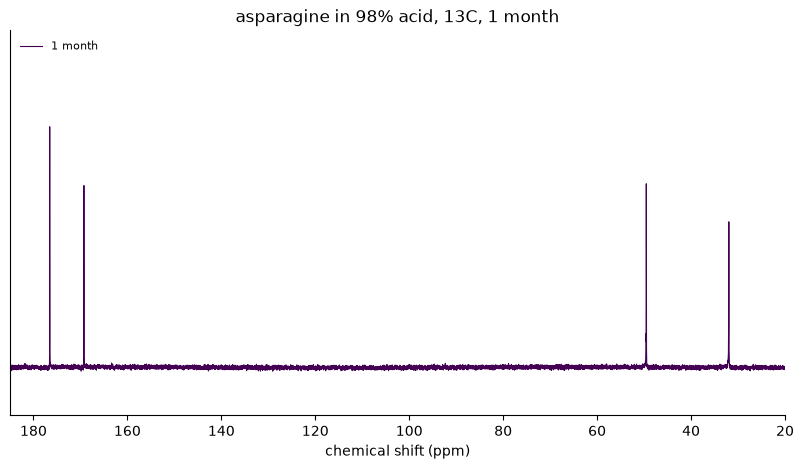

In [27]:
# Asparagine in 98% acid after 1 month: its carbon (13C) spectrum.
carbon_files = nt.data.fetch(
    AMINO_ACID_SPECTRA, "asparagine", acid="98%", nucleus="13C", times=["1month"]
)
asparagine_13c_1month = read_spectrum(carbon_files[0])
title = "asparagine in 98% acid, 13C, 1 month"
fig_c13 = plot_stack([asparagine_13c_1month], ppm_range=(20, 185), scale_region=None, title=title)
plt.show()

In [28]:
# A large peak is at least a tenth as tall as the tallest. Heights are printed as a share of it.
LARGE_PEAK_SHARE = 0.10
large_peaks = pick_peaks(asparagine_13c_1month, (20, 185), min_height=LARGE_PEAK_SHARE)
print("Peaks at least a tenth as tall as the tallest:")
for peak in large_peaks:
    print(f"   {peak['ppm']:6.2f} ppm, height {peak['height']:.2f}")

Peaks at least a tenth as tall as the tallest:
   176.54 ppm, height 1.00
   169.26 ppm, height 0.76
    49.60 ppm, height 0.14
    49.53 ppm, height 0.76
    31.96 ppm, height 0.60


> **RECORD YOUR ANSWER: the large peaks in the 1 month carbon spectrum**
>
> **What gets saved:** `C13_LARGE_PPM`, a list of positions in ppm.
>
> **Where to look:** the list printed above, and the carbon plot.
>
> **How to fill this in:**
> - `C13_LARGE_PPM`: every large peak, as numbers like `[123.4, 56.7]`. Leave out the small neighbour of the alpha carbon.

<details><summary>Stuck? Open hint 1</summary>

Count only the peaks at least a tenth as tall as the tallest: their heights are printed next to
their positions.

</details>

<details><summary>Stuck? Open hint 2</summary>

Asparagine has four carbons, so expect four large peaks: two near 169 and 177 ppm, one near 50 ppm
and one near 32 ppm. Two peaks about 0.07 ppm apart near 50 ppm are the alpha carbon and its small
neighbour.

</details>

In [29]:
C13_LARGE_PPM = []  # the large carbon peaks at 1 month, like [123.4, 56.7]
nt.record.saved("C13_LARGE_PPM", C13_LARGE_PPM, "the large peaks in the 1 month carbon spectrum")

**Not saved yet** `C13_LARGE_PPM = []`: the large peaks in the 1 month carbon spectrum. Still empty: fill it in above.

## Part 4: Verdict and comparison

### What you need

Pick one:
- **Survives:** its peaks from hydrogens on carbon stay in place for the month and keep their sizes
  relative to each other, and no new peaks appear.
- **Side chain changed:** new peaks with the same pattern grow close to the old ones, while the old
  ones shrink. The backbone is intact; the side chain reacted.
- **Breaks down:** its peaks from hydrogens on carbon shrink or vanish while peaks from the products
  appear and grow.
- **Unsure:** the data do not settle it. Say why in your note.

If the side-chain amide turned into a carboxylic acid group (COOH), asparagine would become aspartic
acid and glutamine would become glutamic acid. The optional cell under **Look closer**, below, lays
that amino acid's spectrum over yours.

> **RECORD YOUR ANSWER: your decision on your amino acid**
>
> **What gets saved:** `CALL`, `PRODUCT`, `CONFIDENCE` and `NOTE`, four short answers in quotes.
>
> **Where to look:** your backbone peak and the lost, new and kept peaks you saved above.
>
> **How to fill this in:**
> - `CALL`: your decision, one of the four above: `"survives"`, `"side chain changed"`, `"breaks down"` or `"unsure"`
> - `PRODUCT`: what the side chain may have become, in words; `"none"`; or `""` if you have no idea yet
> - `CONFIDENCE`: how sure you are: `"low"`, `"medium"` or `"high"`
> - `NOTE`: anything your reviewer should know. For the asparagine 98% hand-in (`"ASN-K"`), say how the 98% result differs from the 81% worked case.

<details><summary>Stuck? Open hint 1</summary>

Is your backbone peak in KEPT_PPM? Is anything in NEW_PPM?

</details>

<details><summary>Stuck? Open hint 2</summary>

If the backbone peak stays and new peaks with the same pattern grow beside it, the side chain
changed. If it stays and nothing new appears, the amino acid survives. If it vanishes and unrelated
peaks appear, it breaks down.

</details>

In [30]:
CALL = ""  # your decision: "survives", "side chain changed", "breaks down" or "unsure"
PRODUCT = ""  # what the side chain may have become, "none", or "" if no idea yet
CONFIDENCE = ""  # "low", "medium" or "high"
NOTE = ""  # anything your reviewer should know; for "ASN-K", how it differs from the 81% case

nt.record.write_down("CALL", CALL, case_name, "call")
nt.record.write_down("PRODUCT", PRODUCT, case_name, "product_guess")
nt.record.write_down("CONFIDENCE", CONFIDENCE, case_name, "confidence")
nt.record.write_down("NOTE", NOTE, case_name, "note")

**Not saved yet** `CALL = ''`: write your decision for asparagine: one of "survives", "breaks down", "side chain changed" or "unsure" ("unsure" is a fair answer).

**Not saved yet** `PRODUCT = ''`: write what you think asparagine turned into, "none" if nothing new formed, or leave "" if you have no idea yet.

**Not saved yet** `CONFIDENCE = ''`: write the confidence for asparagine: one of "low", "medium" or "high".

**Saved** `NOTE = ''`: no note for asparagine. That is fine.

### Your verdict

Your verdict is everything you recorded about your case, in one table: your decision, the peaks
behind it, the product and how sure you are. To change it, edit a line above and run this cell again.
The alanine line is the filled example from Part 1.

In [31]:
verdicts = nt.record.build_verdict(
    {
        CASE: {
            "call": CALL,
            "lost_ppm": LOST_PPM,
            "new_ppm": NEW_PPM,
            "kept_ppm": KEPT_PPM,
            "product_guess": PRODUCT,
            "confidence": CONFIDENCE,
            "note": NOTE,
        }
    },
    names={CASE: f"{case_name}, {case_acid}"},
    examples={"alanine, 98% (example)": ALA_EXAMPLE},
)
MY_VERDICT = verdicts[CASE]  # this notebook has one case

| | decision | lost peaks (ppm) | new peaks (ppm) | kept peaks (ppm) | product guess | confidence | note |
|---|---|---|---|---|---|---|---|
| **alanine, 98% (example)** | survives | none | none | 4.63, 1.99 | none | high | The NH3+ signal near 6.8 ppm fades: hydrogens swapping with the acid's deuterium, not breakdown. |
| **asparagine, 81%** | (empty) | none | none | none | (empty) | (empty) | (empty) |

  asparagine, 81%: still empty: decision, lost peaks, new peaks, kept peaks, product guess, confidence. An empty peak list is fine if there were none, and "unsure" is a fair answer.
Nothing here blocks your hand-in. Change any answer above and run the cells again to update it.


The notebook holds no published decision for these amino acids, so the next cell points you to Table 1
of the paper (M. D. Seager et al. 2024, *Astrobiology* 24, 386; [open full text](https://pmc.ncbi.nlm.nih.gov/articles/PMC11035925/)).
The table lists what happens to each amino acid in 98% and in 81% acid. Find your case there and
compare it with your decision. Write what you found in `NOTE` in Part 4, then run the cells from there
down again.

In [32]:
feedback = []
if nt.record.revealed("amino-acid"):
    key = nt.answers.load("amino_acids")
    published = nt.answers.case(key, CASE)
    feedback = nt.checks.check_verdict(MY_VERDICT, published)
    nt.checks.show(feedback, "Your verdict")

Make your prediction first: fill in the prediction cell above and run it, then run this cell again.


### Look closer (optional): test one idea

If the side-chain amide turned into a carboxylic acid group, asparagine would become aspartic acid and
glutamine would become glutamic acid. The next cell lays your 1 month spectrum over that amino acid,
recorded in the same acid. Do any new peaks of yours have the same shape and spacing as its peaks?
It was measured as a separate sample.

Two hydrogen spectra from separate samples match when the peaks have the same pattern (number of
lines and their spacing) and sit within 0.05 ppm of each other. From 0.05 to 0.1 ppm apart, hydrogen
alone does not settle it: compare carbon spectra, where within 0.1 ppm is a match. More than 0.1
ppm apart is not a match. The same molecule sits 0.01 to 0.07 ppm apart between samples in this data.

ASP 1H 81% w/w D2SO4: 1 spectra, all cached
Data: Seager, M. D.; Seager, S.; Bains, W.; Petkowski, J. J. (2023). Stability of Biogenic Amino Acids in Concentrated Sulfuric Acid: Implications for the Habitability of Venus' Clouds (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.8381013 (CC BY 4.0). Paper: Seager et al. 2024, Astrobiology 24, 386 (ADS 2024AsBio..24..386S).


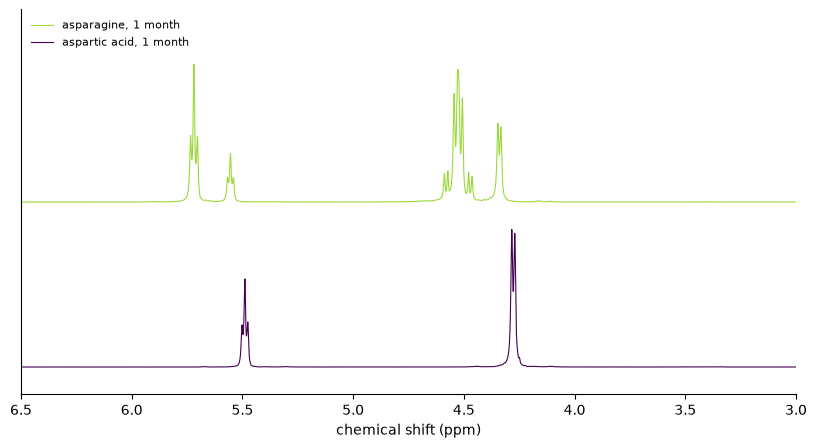

In [33]:
# If the side chain's amide became a carboxylic acid (COOH), this is what it became.
product_name = "aspartic acid" if case_name == "asparagine" else "glutamic acid"
product_files = nt.data.fetch(AMINO_ACID_SPECTRA, product_name, acid=case_acid, times=["1month"])
product = read_spectrum(product_files[0])
labels = [f"{product_name}, 1 month", f"{case_name}, 1 month"]
fig_product = plot_stack(
    [product, case_spectra[-1]],
    ppm_range=(3.0, 6.5),
    scale_region=(3.0, 6.5),
    title=None,
    labels=labels,
)
plt.show()

## Hand-in

> **SAVE YOUR HAND-IN: your amino acid hand-in**
>
> **What gets saved:** in `handin/`: your stack, the carbon plot and `verdict.json` (your backbone signal, carbon peaks, verdict, peak lists and feedback).
>
> **Where to look:** nothing new to fill in: the cell uses what you recorded above.
>
> **How to fill this in:**
> - Run the cell. With `CASE = "ASN-K"`, these files are your hand-in for the NMR project step "Can a molecule change but not fall apart?": the stack is your image of the stacked spectra, and `verdict.json` holds your note.
> - Nothing is sent for review until you run `nt.portal.submit()` in the last line of the cell.
> - In Colab: open the folder icon on the left, then `handin/amino-acid-verdict`, and download each file before you close the tab.

<details><summary>Stuck? Open hint 1</summary>

If the figure is missing from the list it prints, run the cell that draws it, then this cell again.

</details>

<details><summary>Stuck? Open hint 2</summary>

If it says a name is not defined, run the notebook from the top (Runtime > Run all in Colab).

</details>

In [34]:
backbone_ppm = BACKBONE_PPM
if BACKBONE_PPM is ...:
    backbone_ppm = None  # not chosen yet

nt.record.handin(
    "amino-acid-verdict",
    figures={"stack_" + CASE: fig_case, "carbon_1month": fig_c13},
    verdict={
        "case": CASE,
        "backbone_ppm": backbone_ppm,
        "verdict": MY_VERDICT,
        "c13_large_ppm": C13_LARGE_PPM,
        "my_peaks_ppm": case_peaks_ppm,
        "feedback": feedback,
    },
    numbers={"case": CASE, "call": MY_VERDICT["call"], "product": MY_VERDICT["product_guess"]},
    question="amino-acid",
    traps=nt.checks.traps_flagged(case_traps),
)
# nt.portal.submit()

Hand-in saved (offline mode: kept on this computer).
Saved for your hand-in:
   handin/amino-acid-verdict/stack_ASN-H.png
   handin/amino-acid-verdict/carbon_1month.png
   handin/amino-acid-verdict/verdict.json
Offline mode: attach these files on your step page. When you are connected to Rakiura, they are added for you.


## Part 5 (Extra): a change you cannot watch

Serine's side chain ends in a hydroxyl group (OH). Concentrated sulfuric acid can attach a sulfate
to that OH, giving O-sulfoserine (serine with an -OSO3H group on its side chain). If that happens
faster than the first measurement, every spectrum in the series shows the product, and the series
looks flat. Here the reference compound is O-sulfoserine itself, measured on its own.

You need three serine (SER) files in 98% acid, from the same dataset:
- 1 day: SZSSea-SER-D2SOlock-1H-04042023_1 (1).zip, in the folder "aa 1H 98 1day original data"
- 8 days: SZSSea-SER-8day-D2SO4lock-1H-04102023_1.zip, in "aa 1H 98 1week original data"
- 1 month: SZSSea-SER-1month-D2SO4lock-1H-05102023_1.zip, in "aa 1H and 13C 98 1month original data"

Leave the 8 day and 1 month ppm scales alone: in them the acid peak drifts by a few hundredths of a
ppm while serine's peaks stay put.

The 1 day file needs one correction. Its ppm scale was set differently when it was recorded: its
acid peak sits at about 11.08 ppm, not near 11.5, and every peak in it sits about 0.38 ppm lower
than in the 8 day file (4.59 matches 4.97, and 6.83 matches 7.22). The next cell adds 0.38 to its
ppm axis before it stacks the three.

O-sulfoserine was measured in the same acid: file SZSSea-OSulfLSer-K-1Day-1H, in the folder
"sulfSer-oxMet-oxCys-sulfCys 1H and 13C 98 1day original data". The cell lays it over the serine
stack. Compare the peaks from hydrogens on carbon, between 4.8 and 5.3 ppm.

**Predict:** will serine's time series show the change?

In [35]:
# Serine in 98% acid at 1 day, 8 days and 1 month, and O-sulfoserine measured on its own.
serine_files = nt.data.fetch(AMINO_ACID_SPECTRA, "serine", acid="98%")
serine_1day, serine_8day, serine_1month = [read_spectrum(path) for path in serine_files]
reference_files = nt.data.fetch(AMINO_ACID_SPECTRA, "O-sulfoserine", acid="98%")
o_sulfoserine = read_spectrum(reference_files[0])

SER 1H 98% w/w D2SO4: 3 spectra, all cached
Data: Seager, M. D.; Seager, S.; Bains, W.; Petkowski, J. J. (2023). Stability of Biogenic Amino Acids in Concentrated Sulfuric Acid: Implications for the Habitability of Venus' Clouds (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.8381013 (CC BY 4.0). Paper: Seager et al. 2024, Astrobiology 24, 386 (ADS 2024AsBio..24..386S).
OSulfLSer 1H 98% w/w D2SO4: 1 spectra, all cached
Data: Seager, M. D.; Seager, S.; Bains, W.; Petkowski, J. J. (2023). Stability of Biogenic Amino Acids in Concentrated Sulfuric Acid: Implications for the Habitability of Venus' Clouds (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.8381013 (CC BY 4.0). Paper: Seager et al. 2024, Astrobiology 24, 386 (ADS 2024AsBio..24..386S).


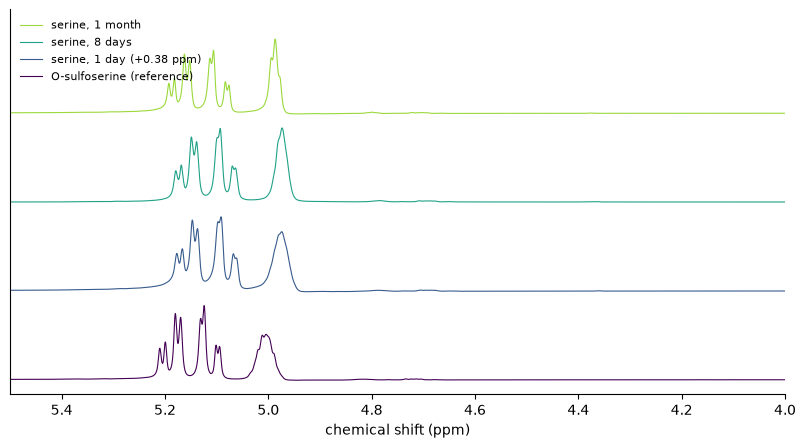

In [36]:
# 4.59 ppm in the 1 day file matches 4.97 in the 8 day file: its scale sits 0.38 ppm low.
SERINE_1DAY_SHIFT_PPM = 0.38
shifted_ppm = serine_1day.ppm + SERINE_1DAY_SHIFT_PPM
# The same intensities on the moved axis.
serine_1day_shifted = serine_1day.with_data(shifted_ppm, serine_1day.intensity)

serine_traces = [o_sulfoserine, serine_1day_shifted, serine_8day, serine_1month]
serine_labels = [
    "O-sulfoserine (reference)",
    "serine, 1 day (+0.38 ppm)",
    "serine, 8 days",
    "serine, 1 month",
]
fig_ser = plot_stack(
    serine_traces, ppm_range=(4.0, 5.5), scale_region=(4.8, 5.3), title=None, labels=serine_labels
)
plt.show()

In [37]:
ACID_REGION_PPM = (10.0, 13.0)  # where the acid's own peak sits: 11.4 to 12.1 ppm in these data

In [38]:
def tallest_ppm(spectrum, ppm_range):
    """Where the tallest point between two ppm values sits. In ACID_REGION_PPM: the acid's peak."""
    ppm, intensity = spectrum.region(*ppm_range)
    return float(ppm[np.argmax(intensity)])

In [39]:
# Where the acid peak sits, then the peaks from hydrogens on carbon between 4.8 and 5.3 ppm.
print(
    f"acid peak in the 1 day file, as recorded: {tallest_ppm(serine_1day, ACID_REGION_PPM):.2f} ppm"
)
print(
    f"acid peak in the 8 day file:              {tallest_ppm(serine_8day, ACID_REGION_PPM):.2f} ppm"
)

for label, spectrum in zip(serine_labels, serine_traces):
    peaks = pick_peaks(spectrum, ppm_range=(4.8, 5.3), min_height=0.03)
    print(f"{label:26s}", [round(peak["ppm"], 3) for peak in peaks])

acid peak in the 1 day file, as recorded: 11.08 ppm
acid peak in the 8 day file:              11.46 ppm
O-sulfoserine (reference)  [5.185, 5.117, 5.008]
serine, 1 day (+0.38 ppm)  [5.153, 5.084, 4.974]
serine, 8 days             [5.155, 5.08, 4.973]
serine, 1 month            [5.168, 5.1, 4.99]


> **RECORD YOUR ANSWER: what is serine in 98% acid?**
>
> **What gets saved:** `SER_CALL`, `SER_PPM`, `OSS_PPM` and `SER_NOTE`.
>
> **Where to look:** the stack and the peak lists above.
>
> **How to fill this in:**
> - `SER_CALL`: one of:
>   - `"survives"`: serine's peaks stay in place, keep their sizes relative to each other, and do not match O-sulfoserine's
>   - `"side chain changed"`: serine's peaks match O-sulfoserine's (same pattern, within 0.05 ppm), whether or not they move over the month
>   - `"breaks down"`: peaks from hydrogens on carbon shrink or vanish while peaks from the products appear and grow
>   - `"unsure"`: the comparison does not settle it (say why in `SER_NOTE`)
> - `SER_PPM` and `OSS_PPM`: the positions your call rests on, in serine and in O-sulfoserine, with 0.38 already added to the 1 day positions (the 1 day list printed above already includes it)

<details><summary>Stuck? Open hint 1</summary>

Read the peak lists one line at a time: for each serine peak, is there an O-sulfoserine peak with
the same pattern within 0.05 ppm?

</details>

<details><summary>Stuck? Open hint 2</summary>

Compare serine with the reference at every time point, the 1 day file included (with 0.38 added). A
change that finished before the first spectrum shows against the reference, not between the
serine files.

</details>

In [40]:
SER_CALL = ""  # your call: "survives", "side chain changed", "breaks down" or "unsure"
SER_PPM = []  # serine's peaks your call rests on, as printed above, like [1.234]
OSS_PPM = []  # the O-sulfoserine peaks you compared them with, like [1.234]
SER_NOTE = ""  # anything your reviewer should know, or ""

nt.record.write_down("SER_CALL", SER_CALL, "serine", "call")
nt.record.saved("SER_PPM", SER_PPM, "the serine peaks your call rests on")
nt.record.saved("OSS_PPM", OSS_PPM, "the O-sulfoserine peaks you compared them with")
nt.record.write_down("SER_NOTE", SER_NOTE, "serine", "note")

**Not saved yet** `SER_CALL = ''`: write your decision for serine: one of "survives", "breaks down", "side chain changed" or "unsure" ("unsure" is a fair answer).

**Not saved yet** `SER_PPM = []`: the serine peaks your call rests on. Still empty: fill it in above.

**Not saved yet** `OSS_PPM = []`: the O-sulfoserine peaks you compared them with. Still empty: fill it in above.

**Saved** `SER_NOTE = ''`: no note for serine. That is fine.

> **SAVE YOUR HAND-IN: your serine hand-in**
>
> **What gets saved:** in `handin/`: the serine stack with O-sulfoserine laid over it, and `verdict.json` with your call, the positions it rests on and the 0.38 ppm correction.
>
> **How to fill this in:**
> - Run the cell. These files are your hand-in for the NMR project Extra "Can a molecule change before you measure it?".
> - Nothing is sent for review until you run `nt.portal.submit()` in the last line of the cell.
> - In Colab: open the folder icon on the left, then `handin/serine-verdict`, and download each file before you close the tab.

<details><summary>Stuck? Open hint 1</summary>

If the figure is missing from the list it prints, run the cell that draws it, then this cell again.

</details>

<details><summary>Stuck? Open hint 2</summary>

If it says a name is not defined, run the notebook from the top (Runtime > Run all in Colab).

</details>

In [41]:
nt.record.handin(
    "serine-verdict",
    figures={"stack_serine": fig_ser},
    verdict={
        "call": SER_CALL,
        "serine_ppm": SER_PPM,
        "o_sulfoserine_ppm": OSS_PPM,
        "note": SER_NOTE,
        "shift_1day_ppm": SERINE_1DAY_SHIFT_PPM,
    },
    numbers={"SER_call": SER_CALL},
)
# nt.portal.submit()   # uncomment to send this for review

Hand-in saved (offline mode: kept on this computer).
Saved for your hand-in:
   handin/serine-verdict/stack_serine.png
   handin/serine-verdict/verdict.json
Offline mode: attach these files on your step page. When you are connected to Rakiura, they are added for you.
